In [6]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

In [5]:
OUTPUT_DIR = Path(
    "/Users/annapoornaak/Desktop/College /Oral Cancer/Segmentation Output"
)

print("Segmentation Output exists:", OUTPUT_DIR.exists())
print("Location:", OUTPUT_DIR)

Segmentation Output exists: True
Location: /Users/annapoornaak/Desktop/College /Oral Cancer/Segmentation Output


In [7]:
COMPARISON_DIR = OUTPUT_DIR / "Model Comparison"
COMPARISON_DIR.mkdir(parents=True, exist_ok=True)

print("Comparison results will be saved in:")
print(COMPARISON_DIR)


Comparison results will be saved in:
/Users/annapoornaak/Desktop/College /Oral Cancer/Segmentation Output/Model Comparison


In [8]:

history_files = list(
    OUTPUT_DIR.glob("*_results/*_history.csv")
)

print("\nHistory files found:")

for file in history_files:
    print(file)


# Safety check
if len(history_files) == 0:
    raise FileNotFoundError(
        "No *_history.csv files were found inside the model result folders."
    )


History files found:
/Users/annapoornaak/Desktop/College /Oral Cancer/Segmentation Output/unet_resnet34_results/unet_resnet34_history.csv
/Users/annapoornaak/Desktop/College /Oral Cancer/Segmentation Output/deeplabv3plus_results/deeplabv3plus_history.csv
/Users/annapoornaak/Desktop/College /Oral Cancer/Segmentation Output/mobile_unet_results/mobile_unet_history.csv


In [9]:

histories = {}

for file in history_files:

    # Example:
    # /Segmentation Output/unet_resnet34_results/
    #     unet_resnet34_history.csv

    model_name = file.stem.replace("_history", "")

    df = pd.read_csv(file)

    histories[model_name] = df

    print(
        f"\n{model_name}"
        f"\nEpochs: {len(df)}"
        f"\nColumns: {list(df.columns)}"
    )


unet_resnet34
Epochs: 25
Columns: ['dice_coef', 'iou_coef', 'loss', 'val_dice_coef', 'val_iou_coef', 'val_loss']

deeplabv3plus
Epochs: 25
Columns: ['dice_coef', 'iou_coef', 'loss', 'val_dice_coef', 'val_iou_coef', 'val_loss']

mobile_unet
Epochs: 25
Columns: ['dice_coef', 'iou_coef', 'loss', 'val_dice_coef', 'val_iou_coef', 'val_loss']


In [10]:
print("\n" + "=" * 70)
print("MODEL HISTORY FILES")
print("=" * 70)

for model_name, df in histories.items():
    print(model_name, "-> loaded successfully")


# ============================================================
# 6. REQUIRED METRICS
# ============================================================

required_metrics = [
    "dice_coef",
    "iou_coef",
    "loss",
    "val_dice_coef",
    "val_iou_coef",
    "val_loss"
]

print("\nMetric check:")

for model_name, df in histories.items():

    missing = [
        metric
        for metric in required_metrics
        if metric not in df.columns
    ]

    if missing:
        print(model_name, "MISSING:", missing)

    else:
        print(model_name, "OK")


MODEL HISTORY FILES
unet_resnet34 -> loaded successfully
deeplabv3plus -> loaded successfully
mobile_unet -> loaded successfully

Metric check:
unet_resnet34 OK
deeplabv3plus OK
mobile_unet OK


In [11]:
def make_comparison_plot(
    metric,
    title,
    ylabel,
    filename
):

    plt.figure(figsize=(10, 6))

    for model_name, df in histories.items():

        if metric not in df.columns:
            continue

        epochs = range(1, len(df) + 1)

        plt.plot(
            epochs,
            df[metric],
            linewidth=2,
            label=model_name
        )

    plt.xlabel("Epoch")
    plt.ylabel(ylabel)
    plt.title(title)

    plt.legend()
    plt.grid(True, alpha=0.3)

    plt.tight_layout()

    save_path = COMPARISON_DIR / filename

    plt.savefig(
        save_path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    print("Saved:", save_path)

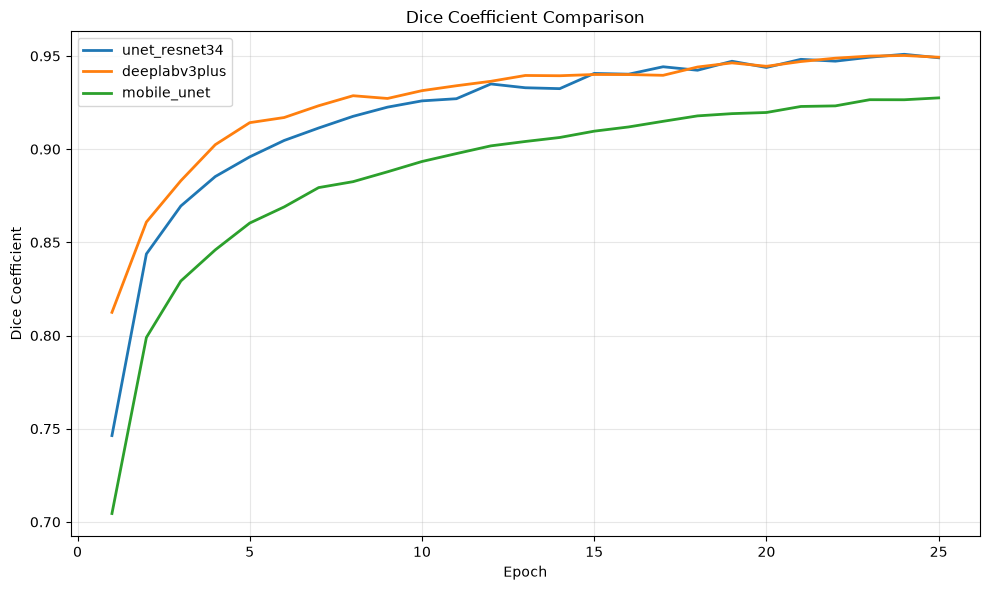

Saved: /Users/annapoornaak/Desktop/College /Oral Cancer/Segmentation Output/Model Comparison/dice_comparison.png


In [12]:
make_comparison_plot(
    "dice_coef",
    "Dice Coefficient Comparison",
    "Dice Coefficient",
    "dice_comparison.png"
)

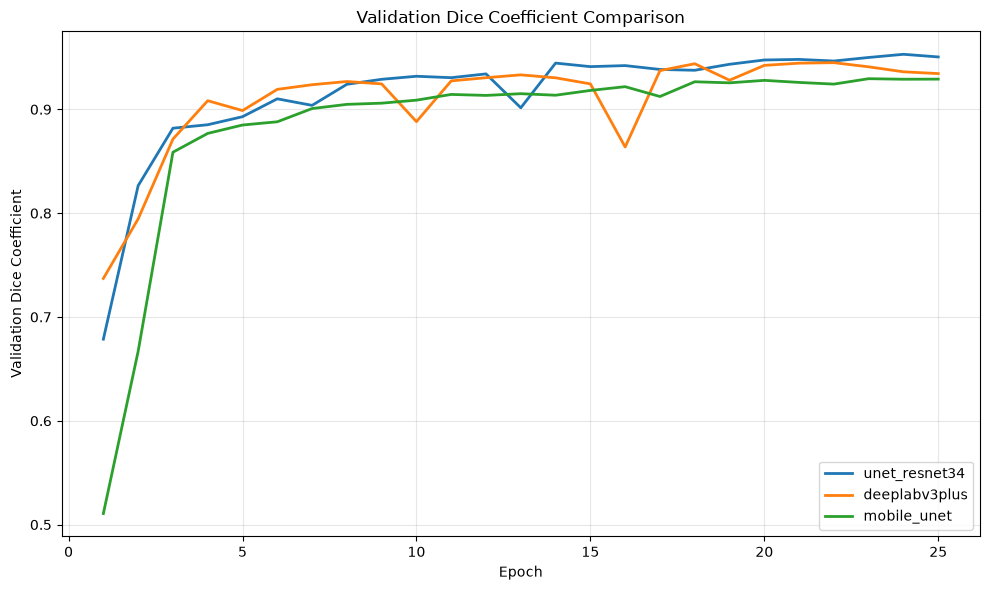

Saved: /Users/annapoornaak/Desktop/College /Oral Cancer/Segmentation Output/Model Comparison/val_dice_comparison.png


In [13]:
make_comparison_plot(
    "val_dice_coef",
    "Validation Dice Coefficient Comparison",
    "Validation Dice Coefficient",
    "val_dice_comparison.png"
)


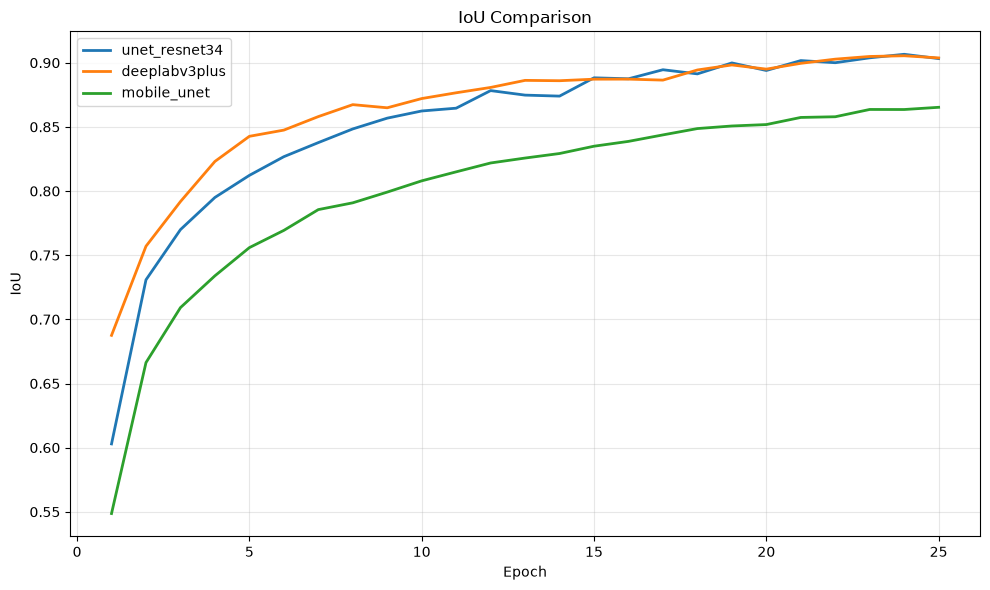

Saved: /Users/annapoornaak/Desktop/College /Oral Cancer/Segmentation Output/Model Comparison/iou_comparison.png


In [14]:
make_comparison_plot(
    "iou_coef",
    "IoU Comparison",
    "IoU",
    "iou_comparison.png"
)

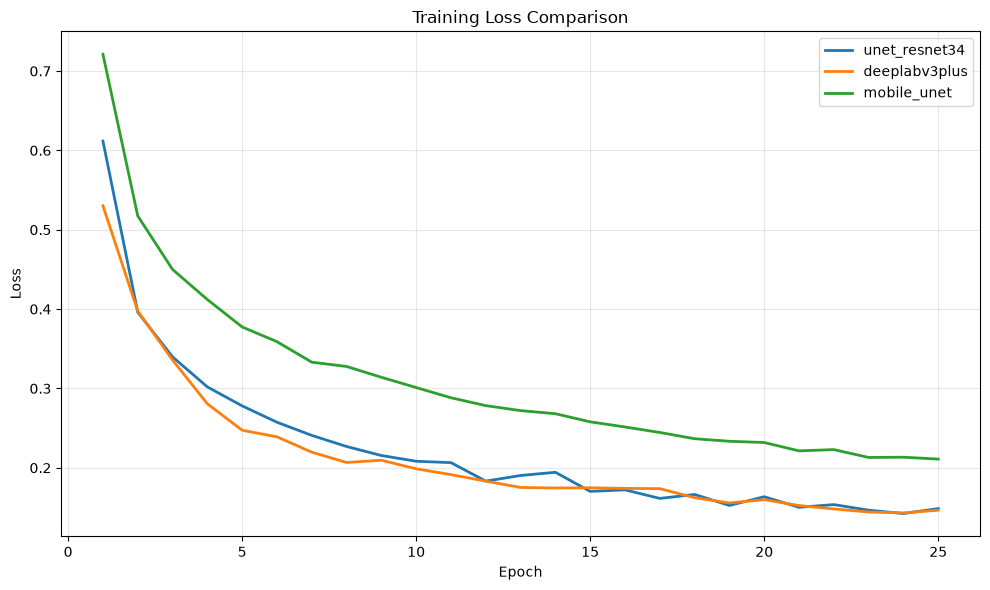

Saved: /Users/annapoornaak/Desktop/College /Oral Cancer/Segmentation Output/Model Comparison/loss_comparison.png


In [15]:
make_comparison_plot(
    "loss",
    "Training Loss Comparison",
    "Loss",
    "loss_comparison.png"
)

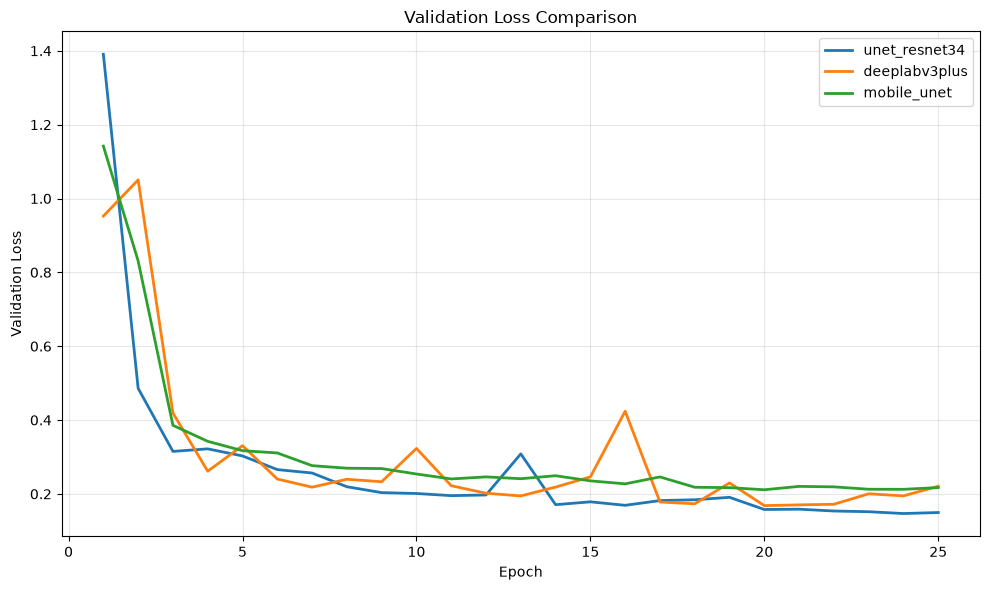

Saved: /Users/annapoornaak/Desktop/College /Oral Cancer/Segmentation Output/Model Comparison/val_loss_comparison.png


In [16]:
make_comparison_plot(
    "val_loss",
    "Validation Loss Comparison",
    "Validation Loss",
    "val_loss_comparison.png"
)

In [17]:
results = []

for model_name, df in histories.items():

    # Find epoch with BEST validation Dice
    best_idx = df["val_dice_coef"].idxmax()

    best_epoch = best_idx + 1

    results.append({

        "Model": model_name,

        "Best Epoch": best_epoch,

        "Best Val Dice":
            df.loc[best_idx, "val_dice_coef"],

        "Val IoU":
            df.loc[best_idx, "val_iou_coef"],

        "Val Loss":
            df.loc[best_idx, "val_loss"],

        "Train Dice":
            df.loc[best_idx, "dice_coef"],

        "Train IoU":
            df.loc[best_idx, "iou_coef"],

        "Train Loss":
            df.loc[best_idx, "loss"]
    })


comparison_df = pd.DataFrame(results)


# ============================================================
# 15. SORT BY BEST VALIDATION DICE
# ============================================================

comparison_df = comparison_df.sort_values(
    by="Best Val Dice",
    ascending=False
).reset_index(drop=True)


# Round numbers
numeric_columns = [
    "Best Val Dice",
    "Val IoU",
    "Val Loss",
    "Train Dice",
    "Train IoU",
    "Train Loss"
]

comparison_df[numeric_columns] = comparison_df[
    numeric_columns
].round(4)

In [18]:
print("\n")
print("=" * 90)
print("SEGMENTATION MODEL COMPARISON")
print("=" * 90)

print(comparison_df.to_string(index=False))



SEGMENTATION MODEL COMPARISON
        Model  Best Epoch  Best Val Dice  Val IoU  Val Loss  Train Dice  Train IoU  Train Loss
unet_resnet34          24         0.9530   0.9106    0.1468      0.9509     0.9066      0.1423
deeplabv3plus          22         0.9450   0.8960    0.1720      0.9488     0.9028      0.1481
  mobile_unet          23         0.9296   0.8690    0.2126      0.9265     0.8636      0.2130


In [19]:
csv_path = (
    COMPARISON_DIR /
    "segmentation_model_comparison.csv"
)

comparison_df.to_csv(
    csv_path,
    index=False
)

print("\nComparison CSV saved:")
print(csv_path)


Comparison CSV saved:
/Users/annapoornaak/Desktop/College /Oral Cancer/Segmentation Output/Model Comparison/segmentation_model_comparison.csv


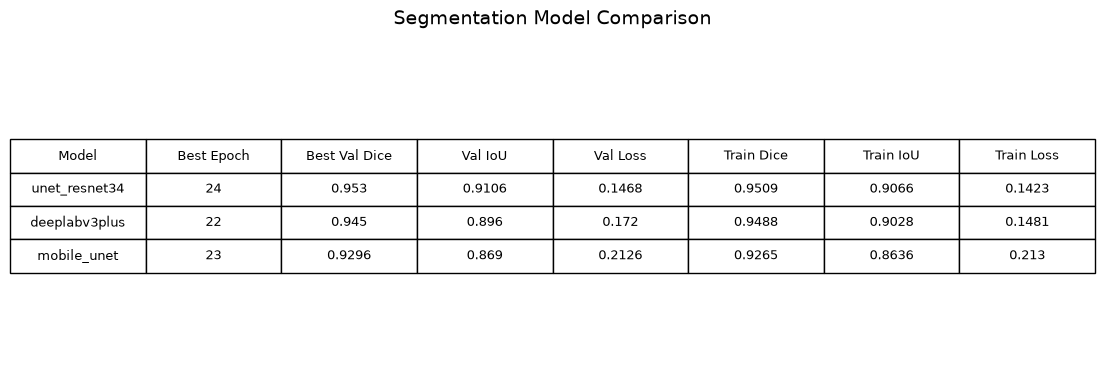

Comparison table image saved:
/Users/annapoornaak/Desktop/College /Oral Cancer/Segmentation Output/Model Comparison/segmentation_model_comparison.png


In [20]:
fig, ax = plt.subplots(
    figsize=(14, 4)
)

ax.axis("off")

table = ax.table(
    cellText=comparison_df.values,
    colLabels=comparison_df.columns,
    cellLoc="center",
    loc="center"
)

table.auto_set_font_size(False)
table.set_fontsize(9)
table.scale(1, 2)

plt.title(
    "Segmentation Model Comparison",
    fontsize=14,
    pad=20
)

table_path = (
    COMPARISON_DIR /
    "segmentation_model_comparison.png"
)

plt.savefig(
    table_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Comparison table image saved:")
print(table_path)

In [21]:
best_model = comparison_df.iloc[0]

print("\n")
print("=" * 70)
print("BEST SEGMENTATION MODEL")
print("=" * 70)

print("Model:", best_model["Model"])
print("Best Epoch:", best_model["Best Epoch"])
print("Best Validation Dice:", best_model["Best Val Dice"])
print("Validation IoU:", best_model["Val IoU"])
print("Validation Loss:", best_model["Val Loss"])



BEST SEGMENTATION MODEL
Model: unet_resnet34
Best Epoch: 24
Best Validation Dice: 0.953
Validation IoU: 0.9106
Validation Loss: 0.1468


In [22]:
summary_path = (
    COMPARISON_DIR /
    "best_model_summary.txt"
)

with open(summary_path, "w") as f:

    f.write("BEST SEGMENTATION MODEL\n")
    f.write("=======================\n\n")

    f.write(
        f"Model: {best_model['Model']}\n"
    )

    f.write(
        f"Best Epoch: {best_model['Best Epoch']}\n"
    )

    f.write(
        f"Best Validation Dice: "
        f"{best_model['Best Val Dice']}\n"
    )

    f.write(
        f"Validation IoU: "
        f"{best_model['Val IoU']}\n"
    )

    f.write(
        f"Validation Loss: "
        f"{best_model['Val Loss']}\n"
    )

print("\nBest model summary saved:")
print(summary_path)

print("\nDONE.")


Best model summary saved:
/Users/annapoornaak/Desktop/College /Oral Cancer/Segmentation Output/Model Comparison/best_model_summary.txt

DONE.
